# Projet — Vote de consensus (ontologie + algorithme génétique)

N personnes doivent choisir **un** séjour de vacances commun. On combine :
- une **ontologie** qui décrit l'espace des options (type, localisation, semaine, coût, animation) ;
- un **simulateur d'opinions** : chaque personne a des préférences, une marge de négociation et des crédits de veto ;
- un **algorithme génétique** qui cherche les meilleurs candidats ;
- un **protocole de consensus** : votes asynchrones + veto payant + assouplissement progressif.

> Prérequis : `pip install -r requirements.txt`. Exécute les cellules dans l'ordre.

## 1. L'ontologie comme catalogue (lecture SPARQL)

On lit `ontologie_vacances.ttl`. Le simulateur extrait, via SPARQL, la liste des destinations et leurs attributs. L'espace de recherche du GA = tous les couples **(destination, semaine)**.

In [1]:
from simulateur import charger_catalogue, lister_candidats

catalogue = charger_catalogue()
candidats = lister_candidats(catalogue)

print(f"{len(catalogue)} destinations, {len(candidats)} candidats (destination x semaine).\n")
for dest_id, infos in catalogue.items():
    print(f"  {infos['nom']:12s} | {infos['type']:8s} | {infos['localisation']:8s} | "
          f"{infos['cout']} EUR | animation {infos['animation']}/10 | "
          f"semaines {infos['semaines'][0]}-{infos['semaines'][-1]}")

12 destinations, 88 candidats (destination x semaine).

  Nice         | Plage    | France   | 600 EUR | animation 7/10 | semaines 27-34
  Chamonix     | Montagne | France   | 700 EUR | animation 4/10 | semaines 27-31
  Barcelone    | Ville    | Espagne  | 550 EUR | animation 9/10 | semaines 26-35
  Rome         | Ville    | Italie   | 650 EUR | animation 8/10 | semaines 26-35
  Corse        | Plage    | France   | 800 EUR | animation 5/10 | semaines 28-33
  Zermatt      | Montagne | Suisse   | 1100 EUR | animation 3/10 | semaines 27-30
  Marrakech    | Ville    | Maroc    | 500 EUR | animation 6/10 | semaines 26-30
  Toscane      | Campagne | Italie   | 600 EUR | animation 2/10 | semaines 27-34
  Ardeche      | Campagne | France   | 400 EUR | animation 3/10 | semaines 27-33
  Costa Brava  | Plage    | Espagne  | 480 EUR | animation 8/10 | semaines 27-35
  Annecy       | Montagne | France   | 550 EUR | animation 5/10 | semaines 27-32
  Lisbonne     | Ville    | Portugal | 520 EUR | ani

## 2. Le simulateur d'opinions

On génère N personnes. Chacune a un type/localisation préféré, une fenêtre de disponibilité, un budget, un niveau d'animation idéal, des **poids** par critère, une **marge de négociation** (tolérance) et des **crédits de veto**.

In [2]:
from simulateur import generer_personnes

personnes = generer_personnes(n=8, catalogue=catalogue, credits_veto=2, graine=42)

for p in personnes:
    semaines = sorted(p.semaines_dispo)
    print(f"  {p.nom:6s} | aime {p.type_prefere:8s} en {p.localisation_preferee:8s} | "
          f"budget {p.budget_max} | anim. {p.animation_preferee}/10 | "
          f"dispo {semaines[0]}-{semaines[-1]} | marge {p.marge:.2f} | vetos {p.credits_veto}")

  Alice  | aime Plage    en Portugal | budget 800 | anim. 8/10 | dispo 30-35 | marge 0.16 | vetos 2
  Bob    | aime Montagne en France   | budget 500 | anim. 6/10 | dispo 30-33 | marge 0.13 | vetos 2
  Carol  | aime Plage    en Portugal | budget 800 | anim. 2/10 | dispo 29-34 | marge 0.33 | vetos 2
  David  | aime Ville    en Italie   | budget 500 | anim. 5/10 | dispo 29-32 | marge 0.19 | vetos 2
  Emma   | aime Plage    en Portugal | budget 500 | anim. 3/10 | dispo 27-32 | marge 0.52 | vetos 2
  Frank  | aime Ville    en Espagne  | budget 800 | anim. 8/10 | dispo 32-34 | marge 0.43 | vetos 2
  Gina   | aime Montagne en Portugal | budget 800 | anim. 5/10 | dispo 27-29 | marge 0.38 | vetos 2
  Hugo   | aime Montagne en Italie   | budget 1000 | anim. 2/10 | dispo 30-32 | marge 0.30 | vetos 2


## 3. La satisfaction d'un candidat

`satisfaction(personne, candidat)` renvoie un score dans `[0, 1]` (adéquation pondérée). Regardons ce que vaut une même destination pour chaque personne.

In [3]:
from simulateur import attributs_candidat, satisfaction

exemple = ("barcelone", 31)
attrs = attributs_candidat(catalogue, exemple)
print(f"Candidat : {attrs['nom']} ({attrs['type']}, {attrs['localisation']}) semaine {attrs['semaine']}\n")

for p in personnes:
    print(f"  {p.nom:6s} : satisfaction = {satisfaction(p, attrs):.2f}")

Candidat : Barcelone (Ville, Espagne) semaine 31

  Alice  : satisfaction = 0.69
  Bob    : satisfaction = 0.69
  Carol  : satisfaction = 0.54
  David  : satisfaction = 0.78
  Emma   : satisfaction = 0.60
  Frank  : satisfaction = 0.84
  Gina   : satisfaction = 0.45
  Hugo   : satisfaction = 0.58


## 4. L'algorithme génétique seul

Sans vote ni veto, le GA cherche le candidat qui maximise la **fitness** = `0.5 * moyenne + 0.5 * minimum` des satisfactions. Le terme `min` force l'équité : on évite une solution qui sacrifie quelqu'un.

In [4]:
from consensus_ga import meilleur_candidat_ga

res_ga = meilleur_candidat_ga(catalogue, personnes, graine=42)
a = res_ga.attrs
print(f"Meilleur candidat (GA seul) : {a['nom']} ({a['type']}, {a['localisation']}) semaine {a['semaine']}")
print(f"Satisfactions : {res_ga.satisfactions}")
print(f"Moyenne {sum(res_ga.satisfactions.values())/len(res_ga.satisfactions):.2f} | "
      f"min {min(res_ga.satisfactions.values()):.2f}")

Meilleur candidat (GA seul) : Annecy (Montagne, France) semaine 32


Satisfactions : {'Alice': 0.672, 'Bob': 0.957, 'Carol': 0.639, 'David': 0.813, 'Emma': 0.686, 'Frank': 0.632, 'Gina': 0.683, 'Hugo': 0.827}
Moyenne 0.74 | min 0.63


## 5. Le protocole de consensus complet

On lance maintenant la boucle : à chaque round, le GA propose un leader, les personnes votent dans un **ordre aléatoire** (asynchrone), peuvent **vetoter** (en payant un crédit), et si personne n'est d'accord les seuils **se relâchent** un peu. On affiche le déroulé.

In [5]:
from consensus_ga import rechercher_consensus

resultat = rechercher_consensus(catalogue, personnes, graine=42, verbeux=True)

print()
a = resultat.attrs
print(f"=> Sejour retenu : {a['nom']} ({a['type']}, {a['localisation']}) semaine {a['semaine']}, {a['cout']} EUR")
print(f"   {'CONSENSUS' if resultat.consensus else 'Meilleur compromis'} en {resultat.nb_rounds} rounds")
print(f"   Satisfactions : {resultat.satisfactions}")

Round  1 | Annecy (sem. 32) | approbations 5/8 | vetos: - | H_votes 0.95 H_explo 0.40 | 
Round  2 | Annecy (sem. 32) | approbations 7/8 | vetos: - | H_votes 0.54 H_explo 0.09 | 
Round  3 | Annecy (sem. 32) | approbations 8/8 | vetos: - | H_votes 0.00 H_explo 0.37 | CONSENSUS

=> Sejour retenu : Annecy (Montagne, France) semaine 32, 550 EUR
   CONSENSUS en 3 rounds
   Satisfactions : {'Alice': 0.672, 'Bob': 0.957, 'Carol': 0.639, 'David': 0.813, 'Emma': 0.686, 'Frank': 0.632, 'Gina': 0.683, 'Hugo': 0.827}


On observe le mécanisme d'**assouplissement** : tant que tout le monde n'approuve pas, les exigences baissent round après round, jusqu'à ce qu'un candidat fasse l'unanimité. Ici le GA protège déjà bien la minorité (satisfaction min élevée), donc aucun veto n'est nécessaire.

## 6. Démonstration du veto payant

Le GA cherche à maximiser la satisfaction **minimale** : il accommode donc spontanément une personne isolée. Pour voir le veto se déclencher, il faut un blocage réel : **deux camps inconciliables**.

Ici, deux personnes ne veulent QUE de la plage, deux autres QUE de la montagne (le type compte pour 80 % de leur satisfaction), et tout le monde est peu flexible. Aucune destination ne peut satisfaire les deux camps : le camp lésé par le leader du moment va **dépenser ses crédits de veto** pour bloquer ce qu'il déteste. Comme le veto est payant, les crédits s'épuisent, puis les marges se relâchent jusqu'à un compromis.

In [6]:
from simulateur import Personne

# Le TYPE pese 80 % : chaque camp est intransigeant sur plage VS montagne.
poids_type = {"type": 0.80, "localisation": 0.08, "semaine": 0.06, "budget": 0.03, "animation": 0.03}

# Camp PLAGE (2 personnes) et camp MONTAGNE (2 personnes), peu flexibles, 2 vetos chacun.
camp_plage = [
    Personne(nom, "Plage", "Espagne", {30, 31, 32, 33}, 800, 8, poids_type, marge=0.15, credits_veto=2)
    for nom in ("Lou", "Manon")
]
camp_montagne = [
    Personne(nom, "Montagne", "Suisse", {30, 31, 32, 33}, 800, 3, poids_type, marge=0.15, credits_veto=2)
    for nom in ("Tom", "Zoe")
]

groupe = camp_plage + camp_montagne
resultat_veto = rechercher_consensus(catalogue, groupe, graine=7, verbeux=True)

print()
a = resultat_veto.attrs
print(f"=> Sejour retenu : {a['nom']} ({a['type']}) semaine {a['semaine']} "
      f"({'CONSENSUS' if resultat_veto.consensus else 'compromis impose'})")
print(f"   Satisfactions : {resultat_veto.satisfactions}")

Round  1 | Costa Brava (sem. 32) | approbations 2/4 | vetos: ['Tom', 'Zoe'] | H_votes 1.00 H_explo 0.09 | 
Round  2 | Costa Brava (sem. 33) | approbations 2/4 | vetos: ['Zoe', 'Tom'] | H_votes 1.00 H_explo 0.14 | 
Round  3 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.40 | 
Round  4 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.22 | 
Round  5 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.17 | 
Round  6 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.28 | 
Round  7 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.25 | 
Round  8 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.30 | 


Round  9 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.05 | 
Round 10 | Costa Brava (sem. 30) | approbations 2/4 | vetos: - | H_votes 1.00 H_explo 0.35 | 


Round 11 | Costa Brava (sem. 30) | approbations 4/4 | vetos: - | H_votes 0.00 H_explo 0.05 | CONSENSUS

=> Sejour retenu : Costa Brava (Plage) semaine 30 (CONSENSUS)
   Satisfactions : {'Lou': 1.0, 'Manon': 1.0, 'Tom': 0.297, 'Zoe': 0.297}


Lecture du résultat : à chaque round, le camp lésé par le leader **dépense un crédit pour le vetoter** (colonne `vetos`), ce qui **force le GA à explorer l'autre type**. Mais comme le veto est **payant** (crédits limités), aucun camp ne peut bloquer indéfiniment : une fois les crédits épuisés et les marges relâchées, le groupe finit par accepter un compromis. C'est exactement l'effet recherché : laisser une minorité écarter ses pires options **sans** lui donner un droit de blocage illimité.

## 7. Compteur d'entropie et arbre de négociation

Pour *visualiser* la dynamique, on mesure l'**entropie** à chaque round :
- **entropie des votes** : 0 = tout le monde d'accord, 1 = groupe coupé en deux. C'est une mesure du **désaccord**.
- **entropie d'exploration** : diversité des destinations présentes dans la population du GA. Élevée = il explore large ; proche de 0 = il s'est concentré sur une option.

On met en scène un cas volontairement explosif : **trois camps inconciliables** (plage, montagne, ville). Chacun vetote les options des autres, ce qui force le GA à **explorer plusieurs branches** avant qu'un compromis n'émerge.

In [7]:
from visualisation import tracer_entropie, tracer_arbre_negociation

# Le TYPE pese 85 % : chaque camp est intransigeant sur le genre de sejour.
poids_type = {"type": 0.85, "localisation": 0.04, "semaine": 0.05, "budget": 0.03, "animation": 0.03}

camp_plage = [Personne(n, "Plage", "Espagne", {30, 31, 32, 33}, 800, 8, poids_type, marge=0.15, credits_veto=3)
              for n in ("Lou", "Manon")]
camp_montagne = [Personne(n, "Montagne", "Suisse", {27, 28, 29, 30}, 1200, 3, poids_type, marge=0.15, credits_veto=3)
                 for n in ("Tom", "Zoe")]
camp_ville = [Personne(n, "Ville", "Italie", {30, 31, 32, 33}, 800, 7, poids_type, marge=0.15, credits_veto=3)
              for n in ("Ali", "Bea")]
groupe3 = camp_plage + camp_montagne + camp_ville

res3 = rechercher_consensus(catalogue, groupe3, graine=1, max_rounds=25, verbeux=True)

explores = {tuple(h["leader"]) for h in res3.historique}
print(f"\n{len(explores)} candidats distincts explores ; sejour retenu : "
      f"{res3.attrs['nom']} (sem. {res3.attrs['semaine']}, {res3.attrs['type']}).")

Round  1 | Costa Brava (sem. 30) | approbations 2/6 | vetos: ['Ali', 'Tom', 'Bea', 'Zoe'] | H_votes 0.92 H_explo 0.53 | 
Round  2 | Rome (sem. 30) | approbations 2/6 | vetos: ['Lou', 'Tom', 'Manon', 'Zoe'] | H_votes 0.92 H_explo 0.35 | 
Round  3 | Corse (sem. 30) | approbations 2/6 | vetos: ['Ali', 'Tom', 'Bea', 'Zoe'] | H_votes 0.92 H_explo 0.42 | 
Round  4 | Marrakech (sem. 30) | approbations 2/6 | vetos: ['Manon', 'Lou'] | H_votes 0.92 H_explo 0.59 | 
Round  5 | Annecy (sem. 30) | approbations 2/6 | vetos: ['Manon', 'Ali', 'Bea', 'Lou'] | H_votes 0.92 H_explo 0.35 | 
Round  6 | Nice (sem. 30) | approbations 2/6 | vetos: - | H_votes 0.92 H_explo 0.36 | 
Round  7 | Nice (sem. 30) | approbations 2/6 | vetos: - | H_votes 0.92 H_explo 0.19 | 
Round  8 | Nice (sem. 30) | approbations 2/6 | vetos: - | H_votes 0.92 H_explo 0.22 | 
Round  9 | Nice (sem. 30) | approbations 2/6 | vetos: - | H_votes 0.92 H_explo 0.14 | 
Round 10 | Nice (sem. 30) | approbations 2/6 | vetos: - | H_votes 0.92 H_ex

### La courbe d'entropie

L'entropie des votes reste haute tant que le groupe est divisé, puis **chute à 0 au moment du consensus**. L'entropie d'exploration fluctue pendant que le GA teste différentes destinations (phase de vetos), puis se tasse quand la recherche se concentre. Les bandes rouges marquent les rounds où un veto a été posé.

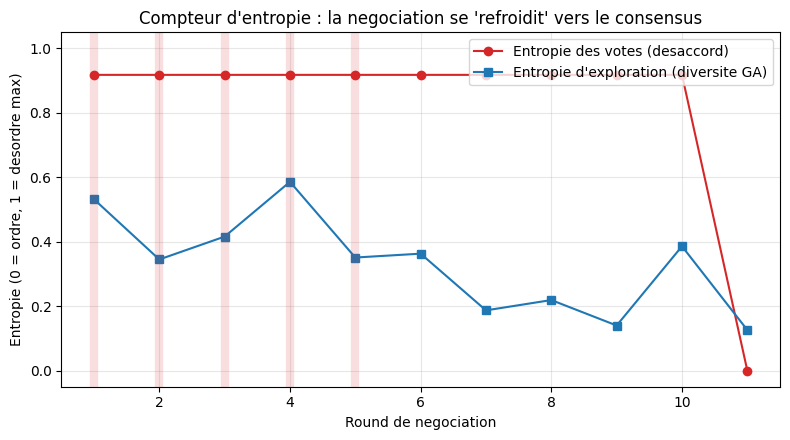

In [8]:
tracer_entropie(res3.historique);

### L'arbre de négociation

Chaque option testée par le GA est un nœud de l'arbre. Les options **vetotées** (branches mortes) sont en rouge, le **consensus** final en vert. On voit concrètement les **différentes branches explorées** : le groupe a essayé plusieurs destinations, chacune rejetée par les camps lésés, avant de converger.

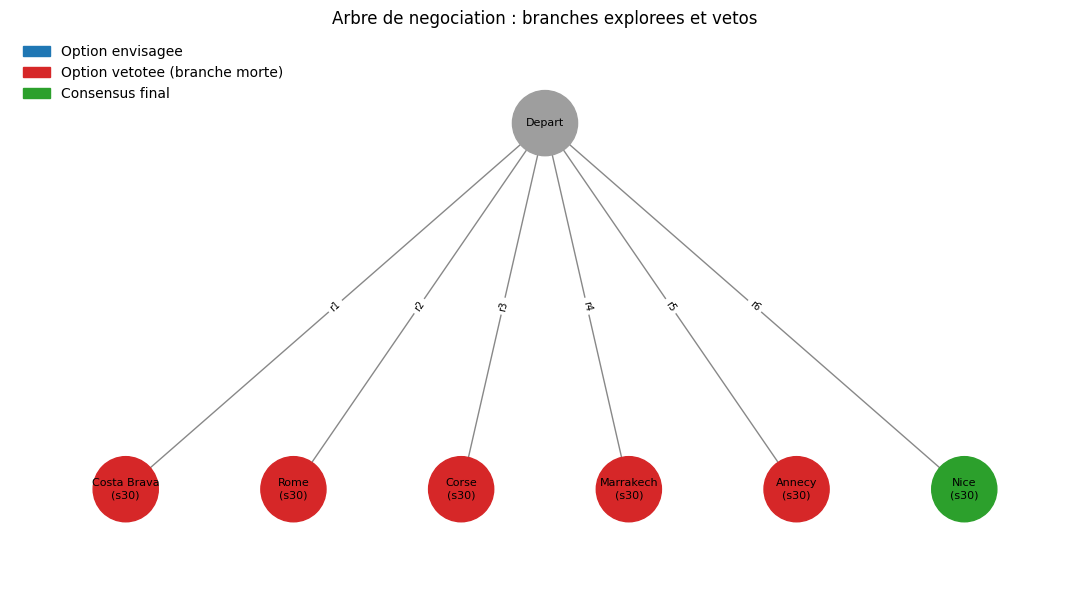

In [9]:
tracer_arbre_negociation(res3.historique);

## 8. Paramètres à régler

Tu peux faire varier (dans `run.py`, `scenario_branches.py` ou ici) :
- `n` : le nombre de personnes ;
- `credits_veto` : plus il est élevé, plus une minorité peut bloquer longtemps (et plus l'arbre a de branches) ;
- `PAS_RELACHEMENT` et le seuil de base (dans `simulateur.py` / `consensus_ga.py`) : vitesse de la négociation ;
- `taille_pop`, `generations_par_round`, `max_rounds` : la puissance de recherche du GA.

En résumé : **l'ontologie définit le terrain de jeu, le GA explore (l'arbre montre les branches), le protocole de vote + veto payant arbitre, et l'entropie mesure le chemin vers le consensus.**